# 6. Reinforcement Learning (Any one)
A. Implement Reinforcement Learning using an example of a maze environment that the
agent needs to explore.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# 1. DEFINE MAZE
maze = np.array([
    [0, 0, 0],
    [1, 0, 1],
    [0, 0, 2]
])

start = (0, 0)
goal = (2, 2)


In [4]:
# 2. INITIALIZE Q-TABLE AND ACTIONS
Q = np.zeros((3, 3, 4))

# Up, Down, Left, Right
moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]

alpha = 0.1
gamma = 0.9
epsilon = 0.2


In [5]:
# 3. TRAIN USING Q-LEARNING
for episode in range(1000):

    state = start

    for step in range(30):

        r, c = state

        # Choose action
        if np.random.rand() < epsilon:
            action = np.random.randint(4)
        else:
            action = np.argmax(Q[r, c])

        dr, dc = moves[action]
        nr, nc = r + dr, c + dc

        # Check walls and boundaries
        if (nr < 0 or nr >= 3 or nc < 0 or nc >= 3
                or maze[nr, nc] == 1):

            next_state = state
            reward = -10

        else:
            next_state = (nr, nc)
            reward = 100 if next_state == goal else -1

        # Update Q-table
        if next_state == goal:
            target = reward
        else:
            target = reward + gamma * np.max(Q[next_state])

        Q[r, c, action] += alpha * (target - Q[r, c, action])

        state = next_state

        if state == goal:
            break

print("Training Completed!")


Training Completed!


In [6]:
# 4. FIND LEARNED PATH
state = start
path = [state]

for step in range(20):

    r, c = state
    action = np.argmax(Q[r, c])

    dr, dc = moves[action]
    next_state = (r + dr, c + dc)

    if (not (0 <= next_state[0] < 3 and
             0 <= next_state[1] < 3) or
            maze[next_state] == 1):
        break

    state = next_state
    path.append(state)

    if state == goal:
        break

print("Learned Path:", path)
print("Goal Reached:", state == goal)


Learned Path: [(0, 0), (0, 1), (1, 1), (2, 1), (2, 2)]
Goal Reached: True


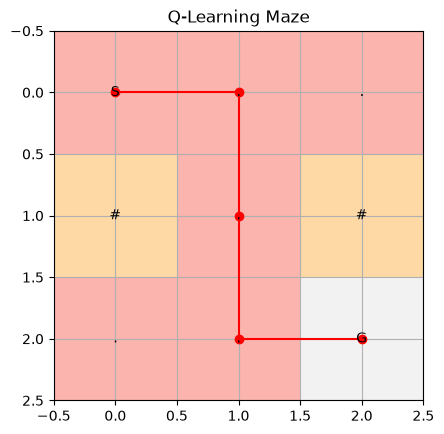

In [7]:
# 5. VISUALIZE MAZE
plt.imshow(maze, cmap="Pastel1")

for r in range(3):
    for c in range(3):
        if (r, c) == start:
            label = "S"
        elif (r, c) == goal:
            label = "G"
        elif maze[r, c] == 1:
            label = "#"
        else:
            label = "."

        plt.text(c, r, label, ha="center", va="center")

plt.plot([c for r, c in path],
         [r for r, c in path], "ro-")

plt.title("Q-Learning Maze")
plt.grid()
plt.show()